# DWML A4: Bank Loan Approval Prediction Using Classification
### `Name: Shreeya Tapaswi`
### `Roll No - 31474`

## Problem Statement

A bank receives thousands of loan applications every month. To minimize
financial risk, the bank wants to predict whether a loan application
should be Approved or Rejected based on applicant details.

The objective of this project is to build classification models that predict
loan approval status.

### Target Variable

- Approved = 1
- Rejected = 0

### Classification Algorithms Used

1. Logistic Regression
2. Decision Tree
3. Naive Bayes
4. Support Vector Machine (SVM)
5. K-Nearest Neighbors (KNN)
6. Random Forest

The models are compared using accuracy, precision, recall, F1-score and ROC-AUC.

## Dataset Description

Dataset: Loan Approval Prediction Dataset

Source:
https://www.kaggle.com/datasets/architsharma01/loan-approval-prediction-dataset

The dataset contains 4,269 loan applications and information about the
applicant's financial and credit profile.

Important attributes include:

- Annual income
- Employment status
- Loan amount
- Loan term
- CIBIL credit score
- Number of dependents
- Asset values
- Loan approval status

The target variable is `loan_status`, which contains:
- Approved
- Rejected

For machine learning:
- Approved = 1
- Rejected = 0

## Import Libraries

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

## Upload Dataset

In [ ]:
uploaded = files.upload()

Saving loan_approval_dataset.csv to loan_approval_dataset.csv


## Load Dataset

In [ ]:
df = pd.read_csv("loan_approval_dataset.csv")

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


## Basic Information

In [ ]:
print("Shape of dataset:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Shape of dataset: (4269, 13)

Column names:
['loan_id', ' no_of_dependents', ' education', ' self_employed', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value', ' loan_status']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value 

## Remove Extra Spaces From Column Names

In [ ]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


## First Five Rows

In [ ]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


## Last Five Rows

In [ ]:
df.tail()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved
4268,4269,1,Graduate,No,9200000,29700000,10,607,17800000,11800000,35700000,12000000,Approved


## Dataset Shape

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 4269
Number of columns: 13


## Data Types

In [ ]:
print(df.dtypes)

loan_id                      int64
no_of_dependents             int64
education                   object
self_employed               object
income_annum                 int64
loan_amount                  int64
loan_term                    int64
cibil_score                  int64
residential_assets_value     int64
commercial_assets_value      int64
luxury_assets_value          int64
bank_asset_value             int64
loan_status                 object
dtype: object


## Statistical Description

In [ ]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


## Check Missing Values

In [ ]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


## Missing Value Visualization

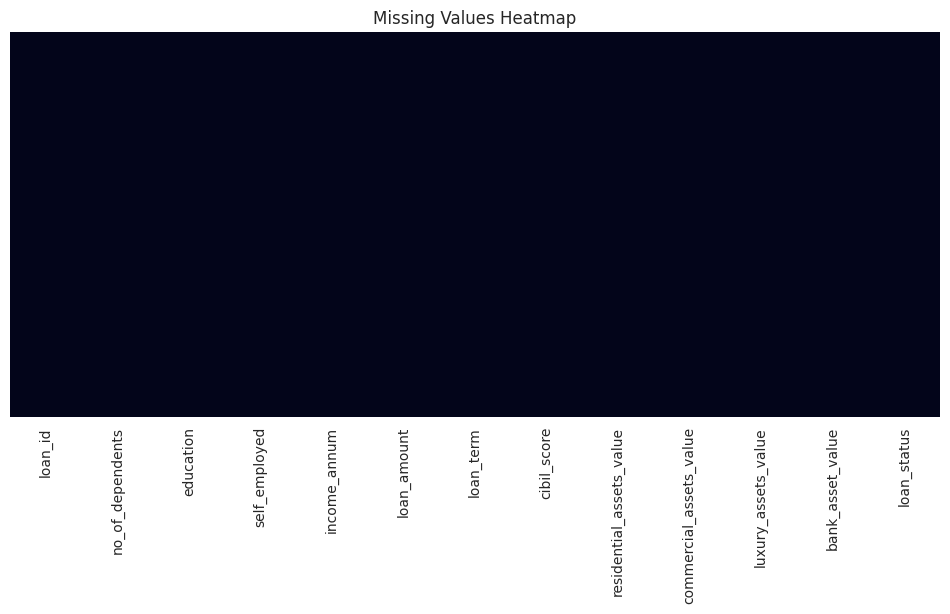

In [ ]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values Heatmap")
plt.show()

## Duplicate Values

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


## Remove Duplicates

In [ ]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (4269, 13)


## Unique Values

In [ ]:
df.nunique()

,0
loan_id,4269
no_of_dependents,6
education,2
self_employed,2
income_annum,98
loan_amount,378
loan_term,10
cibil_score,601
residential_assets_value,278
commercial_assets_value,188


## Target Variable

In [ ]:
for column in df.columns:
    print("\n", column)
    print(df[column].unique()[:20])


 loan_id
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]

 no_of_dependents
[2 0 3 5 4 1]

 education
[' Graduate' ' Not Graduate']

 self_employed
[' No' ' Yes']

 income_annum
[9600000 4100000 9100000 8200000 9800000 4800000 8700000 5700000  800000
 1100000 2900000 6700000 5000000 1900000 4700000  500000 2700000 6300000
 5800000 6500000]

 loan_amount
[29900000 12200000 29700000 30700000 24200000 13500000 33000000 15000000
  2200000  4300000 11200000 22700000 11600000 31500000  7400000 10700000
  1600000  9400000 10300000 14600000]

 loan_term
[12  8 20 10  4  2 18 16 14  6]

 cibil_score
[778 417 506 467 382 319 678 782 388 547 538 311 679 469 794 663 780 736
 652 315]

 residential_assets_value
[ 2400000  2700000  7100000 18200000 12400000  6800000 22500000 13200000
  1300000  3200000  8100000 15300000  6400000 10800000  1900000  5700000
  2900000  1000000 10300000  9500000]

 commercial_assets_value
[17600000  2200000  4500000  3300000  8200000  8300000 14800000  57

## Target Distribution

In [ ]:
print(df["loan_status"].value_counts())

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


## Target Percentage

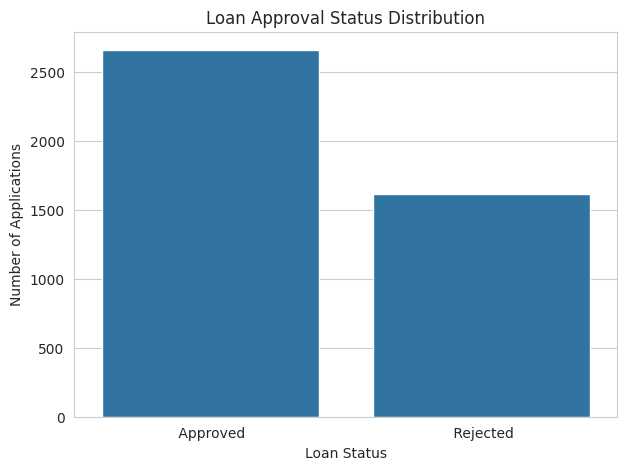

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="loan_status"
)

plt.title("Loan Approval Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")

plt.show()

## Convert Target to 0 and 1

In [ ]:
target_percentage = (
    df["loan_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(target_percentage)

loan_status
Approved    62.22
Rejected    37.78
Name: proportion, dtype: float64


In [ ]:
df["loan_status"] = (
    df["loan_status"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df["loan_status"] = df["loan_status"].map({
    "approved": 1,
    "rejected": 0
})

print(df["loan_status"].value_counts())

loan_status
1    2656
0    1613
Name: count, dtype: int64


In [ ]:
print(df["loan_status"].unique())

[1 0]


In [ ]:
if "loan_id" in df.columns:
    df = df.drop(columns=["loan_id"])

print(df.head())

   no_of_dependents      education self_employed  income_annum  loan_amount  \
0                 2       Graduate            No       9600000     29900000   
1                 0   Not Graduate           Yes       4100000     12200000   
2                 3       Graduate            No       9100000     29700000   
3                 3       Graduate            No       8200000     30700000   
4                 5   Not Graduate           Yes       9800000     24200000   

   loan_term  cibil_score  residential_assets_value  commercial_assets_value  \
0         12          778                   2400000                 17600000   
1          8          417                   2700000                  2200000   
2         20          506                   7100000                  4500000   
3          8          467                  18200000                  3300000   
4         20          382                  12400000                  8200000   

   luxury_assets_value  bank_asset_value  lo

In [ ]:
categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

Categorical columns:
['education', 'self_employed']


In [ ]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

numerical_columns.remove("loan_status")

print("Numerical columns:")
print(numerical_columns)

Numerical columns:
['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']


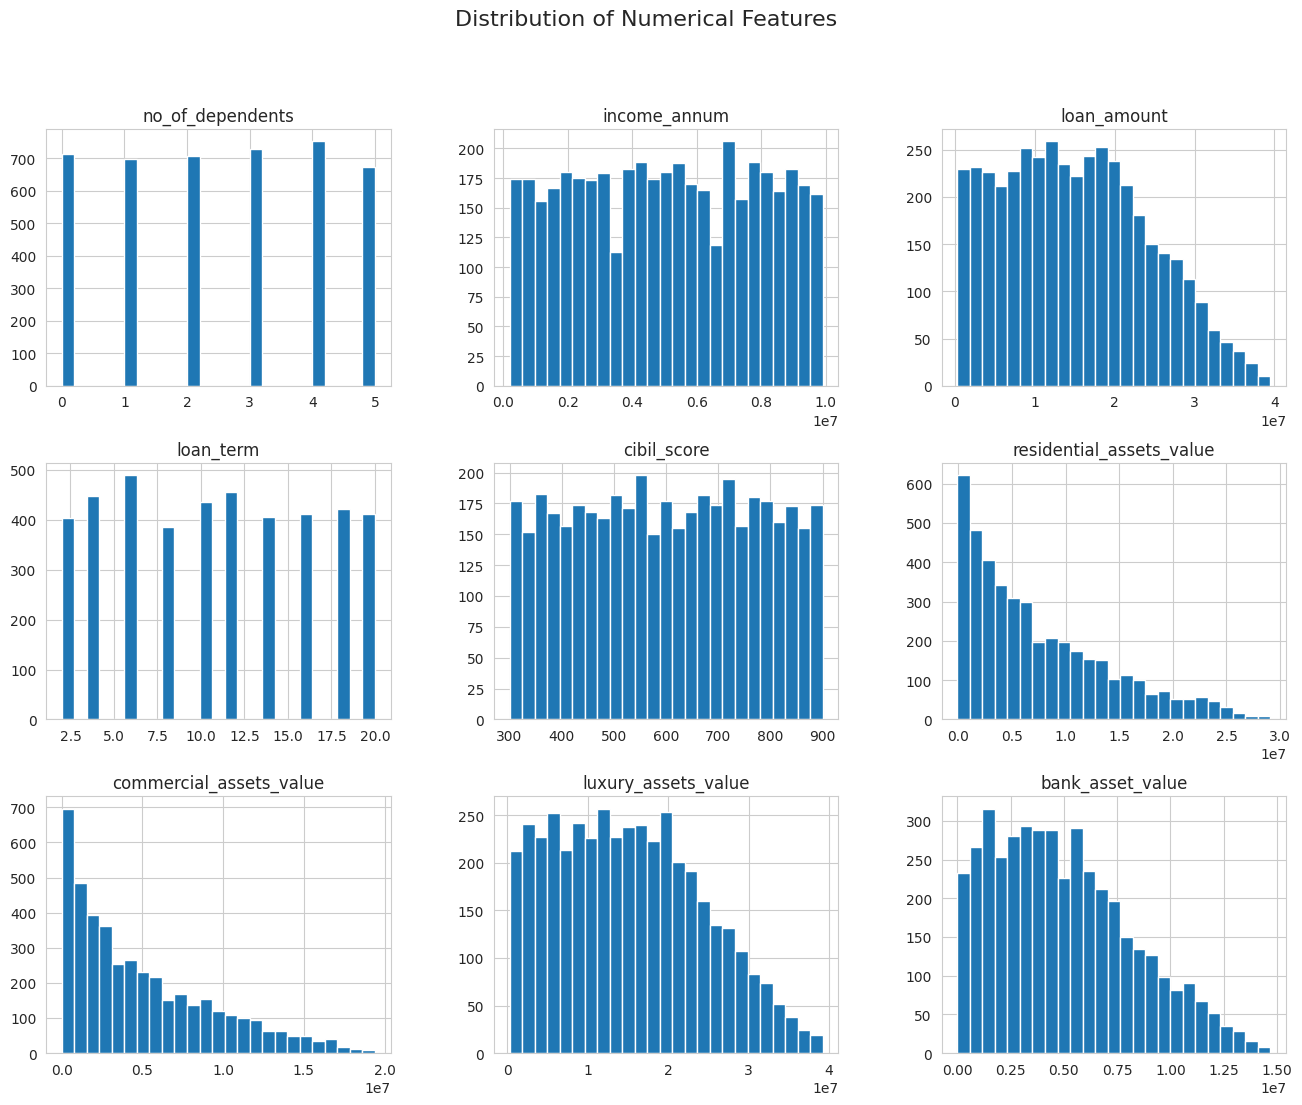

In [ ]:
df[numerical_columns].hist(
    figsize=(16, 12),
    bins=25
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.show()

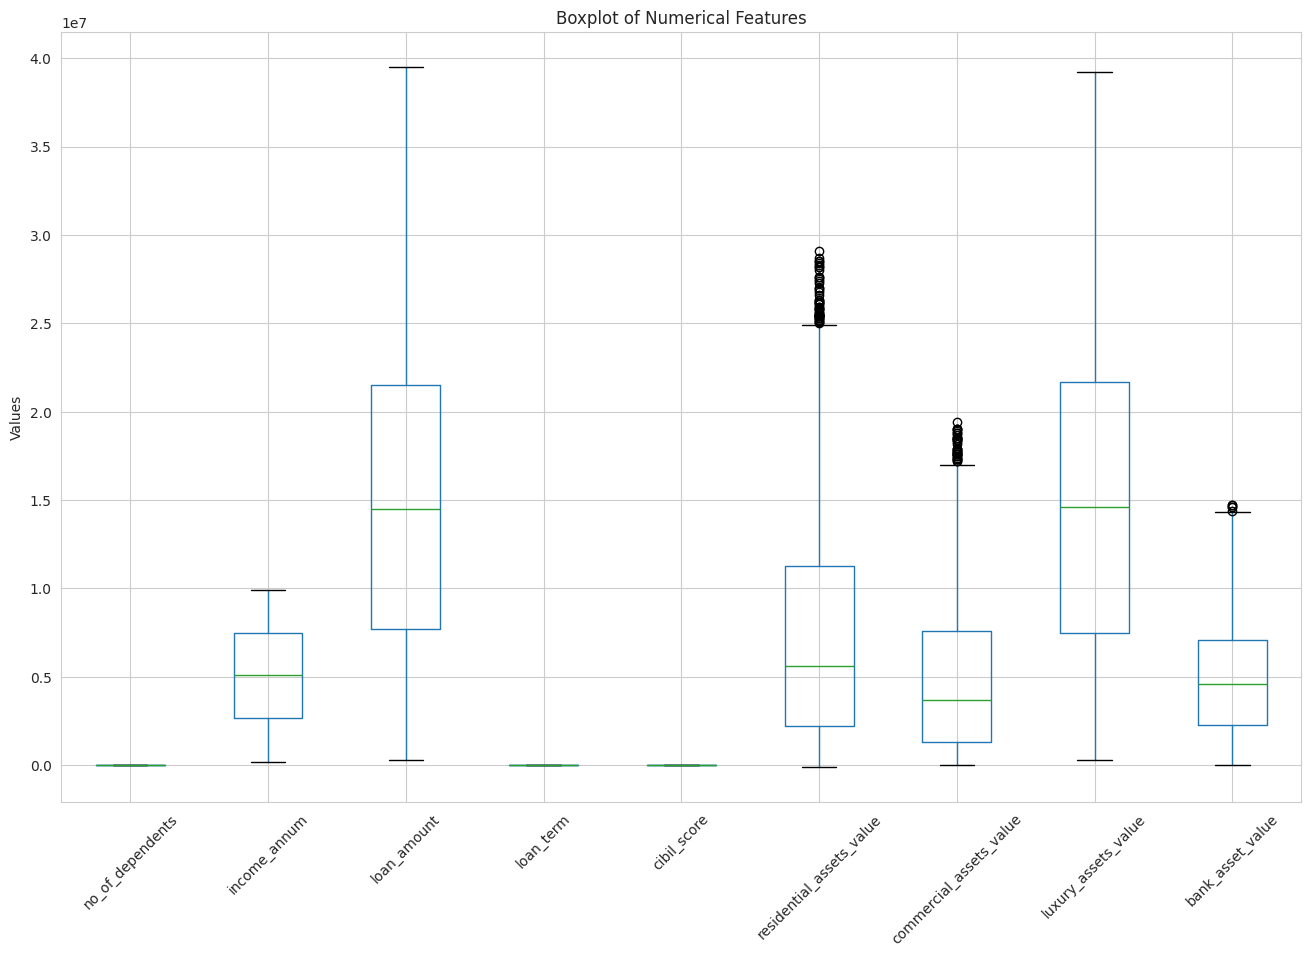

In [ ]:
plt.figure(figsize=(16, 10))

df[numerical_columns].boxplot(
    rot=45
)

plt.title("Boxplot of Numerical Features")
plt.ylabel("Values")

plt.show()

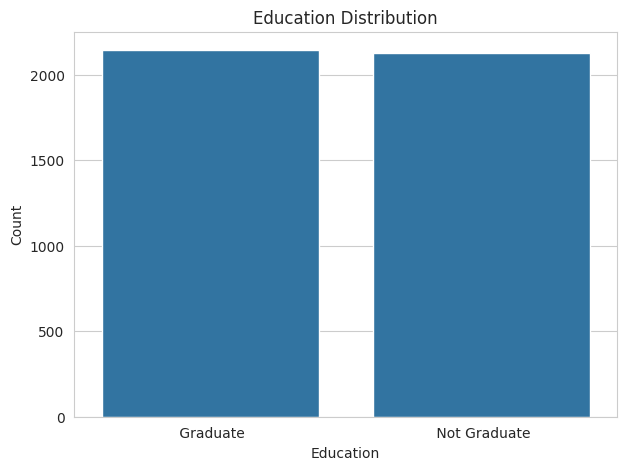

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="education"
)

plt.title("Education Distribution")
plt.xlabel("Education")
plt.ylabel("Count")

plt.show()

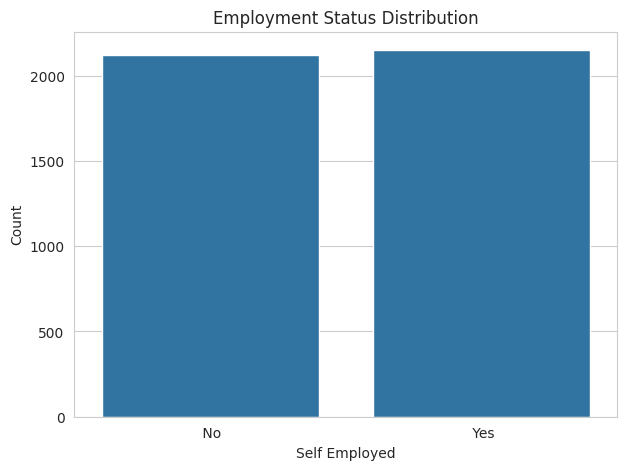

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="self_employed"
)

plt.title("Employment Status Distribution")
plt.xlabel("Self Employed")
plt.ylabel("Count")

plt.show()

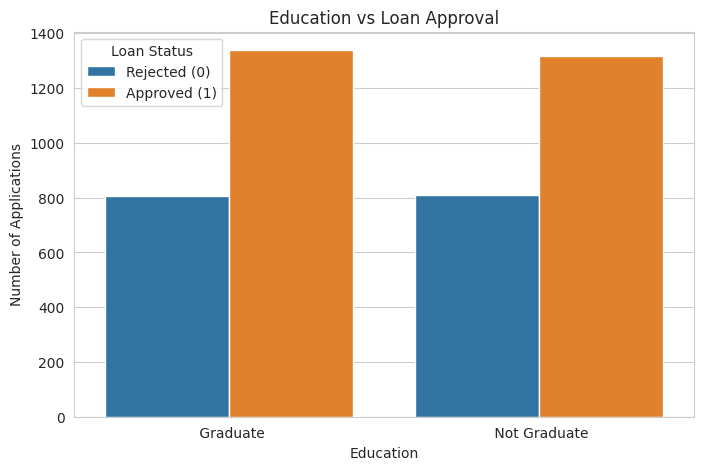

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="education",
    hue="loan_status"
)

plt.title("Education vs Loan Approval")
plt.xlabel("Education")
plt.ylabel("Number of Applications")

plt.legend(
    title="Loan Status",
    labels=["Rejected (0)", "Approved (1)"]
)

plt.show()

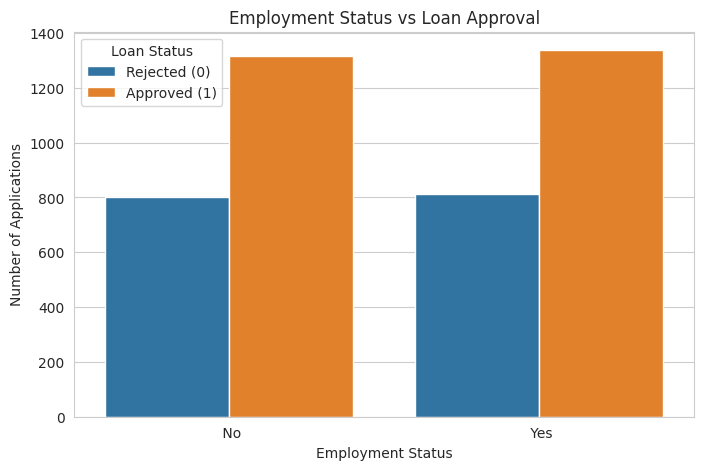

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="self_employed",
    hue="loan_status"
)

plt.title("Employment Status vs Loan Approval")
plt.xlabel("Employment Status")
plt.ylabel("Number of Applications")

plt.legend(
    title="Loan Status",
    labels=["Rejected (0)", "Approved (1)"]
)

plt.show()

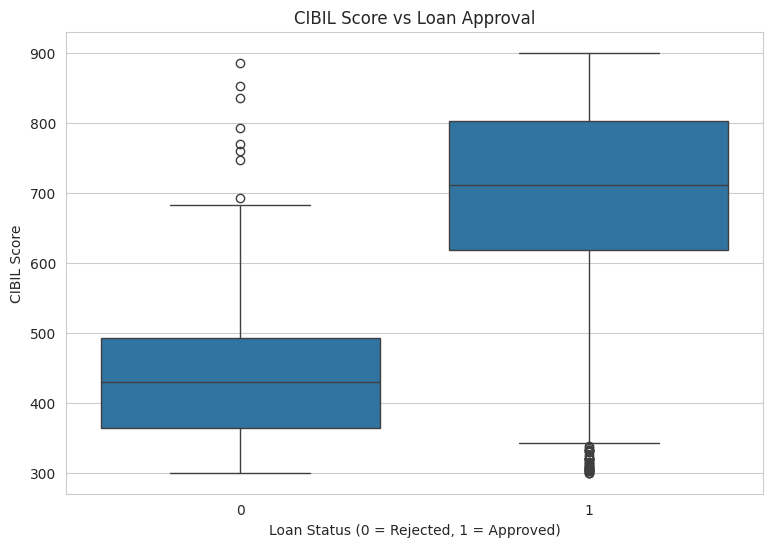

In [ ]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="loan_status",
    y="cibil_score"
)

plt.title("CIBIL Score vs Loan Approval")
plt.xlabel("Loan Status (0 = Rejected, 1 = Approved)")
plt.ylabel("CIBIL Score")

plt.show()

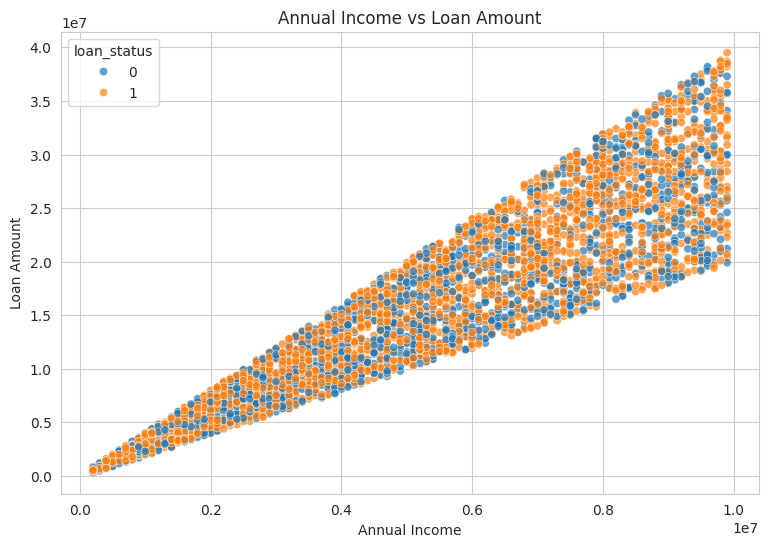

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="income_annum",
    y="loan_amount",
    hue="loan_status",
    alpha=0.7
)

plt.title("Annual Income vs Loan Amount")
plt.xlabel("Annual Income")
plt.ylabel("Loan Amount")

plt.show()

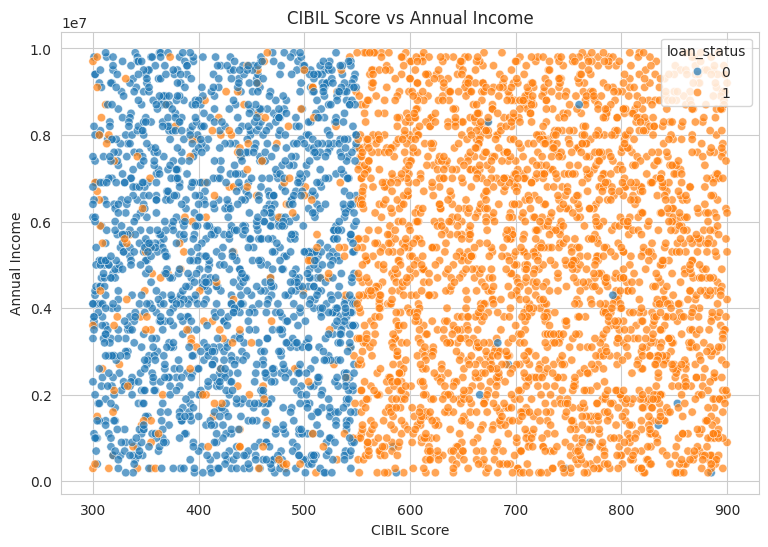

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="cibil_score",
    y="income_annum",
    hue="loan_status",
    alpha=0.7
)

plt.title("CIBIL Score vs Annual Income")
plt.xlabel("CIBIL Score")
plt.ylabel("Annual Income")

plt.show()

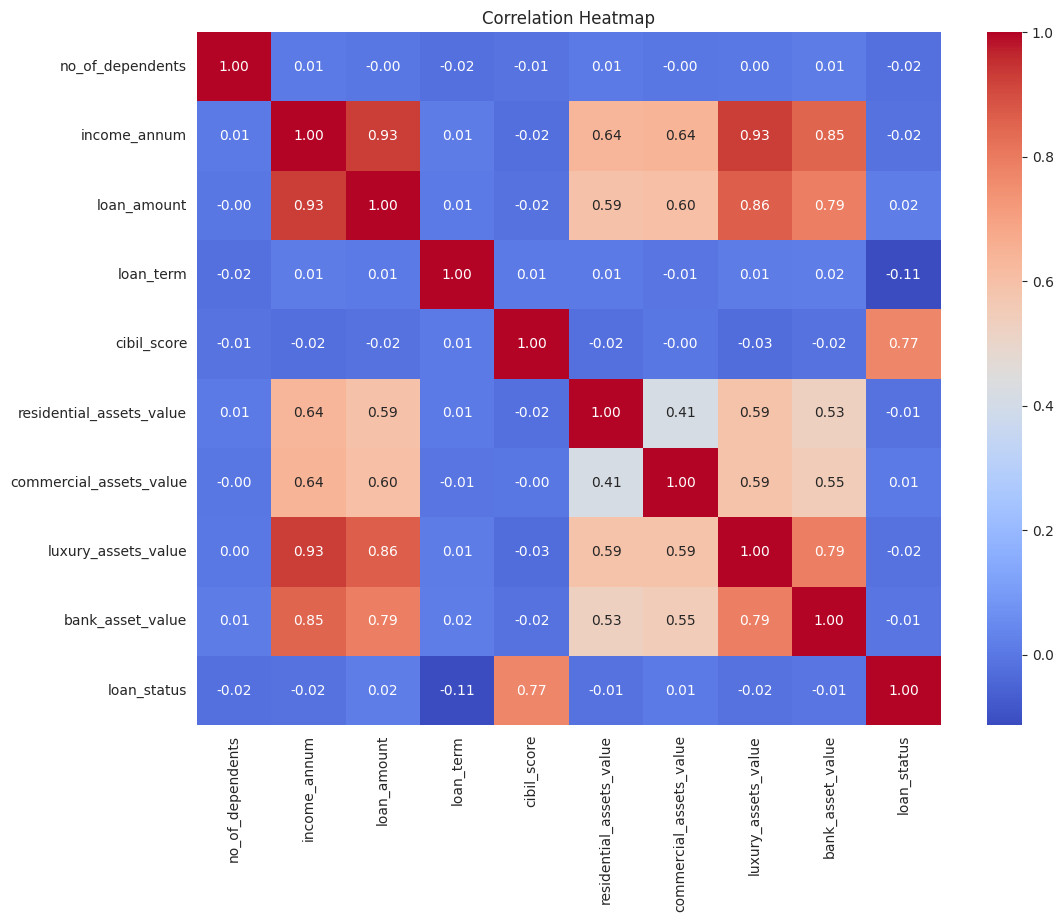

In [ ]:
plt.figure(figsize=(12, 9))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

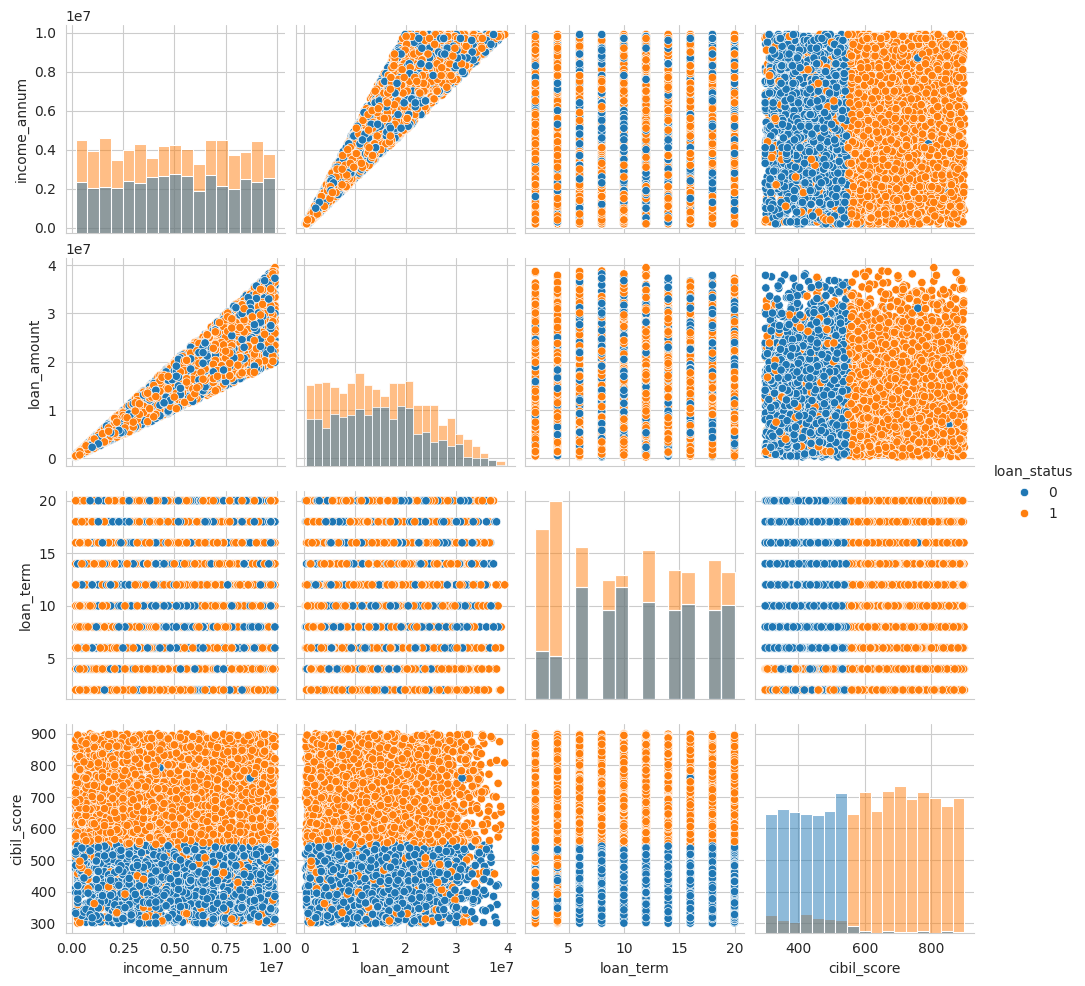

In [ ]:
pairplot_columns = [
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "loan_status"
]

sns.pairplot(
    df[pairplot_columns],
    hue="loan_status",
    diag_kind="hist"
)

plt.show()

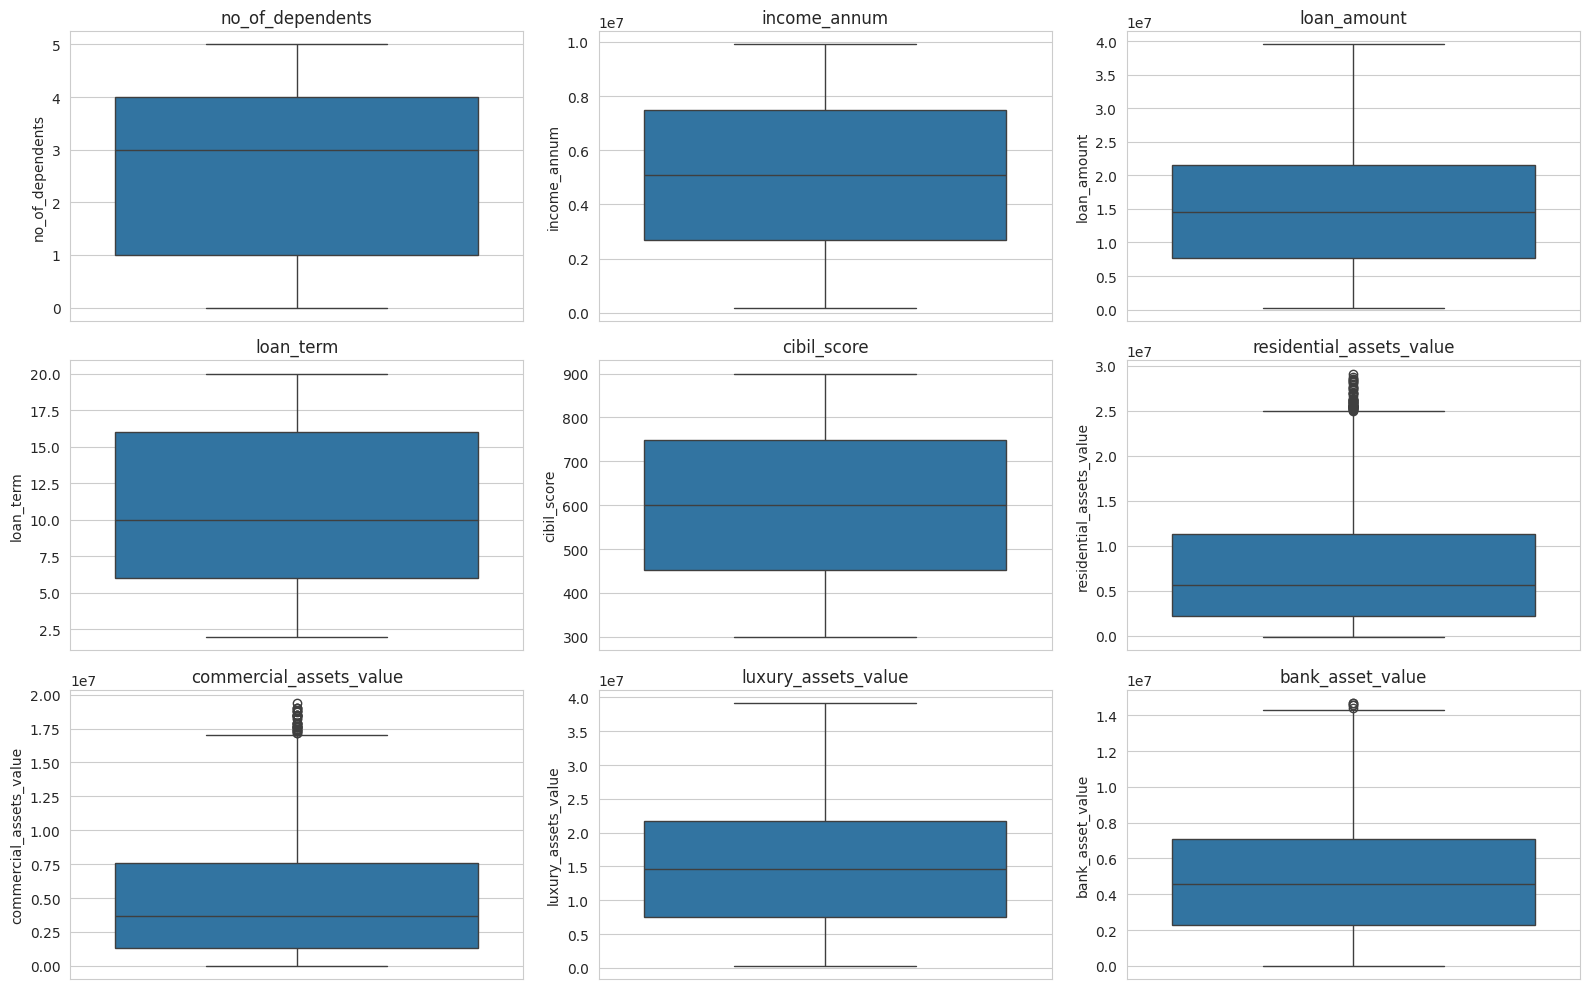

In [ ]:
plt.figure(figsize=(16, 10))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(3, 3, i)

    sns.boxplot(
        y=df[column]
    )

    plt.title(column)

plt.tight_layout()
plt.show()

In [ ]:
X = df.drop(columns=["loan_status"])
y = df["loan_status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4269, 11)
y shape: (4269,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3415, 11)
Testing data: (854, 11)


In [ ]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['education', 'self_employed']
Numerical features: ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']


In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [ ]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Naive Bayes": GaussianNB(),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

print("Models created successfully!")

Models created successfully!


In [ ]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Naive Bayes trained successfully!
SVM trained successfully!
KNN trained successfully!
Random Forest trained successfully!


In [ ]:
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    print(name)
    print(y_pred[:10])
    print()

Logistic Regression
[1 0 1 1 1 1 1 0 1 0]

Decision Tree
[1 0 0 1 1 1 1 0 1 0]

Naive Bayes
[1 0 0 1 1 1 1 0 1 0]

SVM
[1 0 0 1 1 1 1 0 1 0]

KNN
[1 0 0 1 1 1 1 1 1 0]

Random Forest
[1 0 0 1 1 1 1 0 1 0]



In [ ]:
for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Rejected", "Approved"]
        )
    )

Logistic Regression
              precision    recall  f1-score   support

    Rejected       0.90      0.87      0.88       323
    Approved       0.92      0.94      0.93       531

    accuracy                           0.91       854
   macro avg       0.91      0.91      0.91       854
weighted avg       0.91      0.91      0.91       854

Decision Tree
              precision    recall  f1-score   support

    Rejected       0.97      0.97      0.97       323
    Approved       0.98      0.98      0.98       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854

Naive Bayes
              precision    recall  f1-score   support

    Rejected       0.93      0.93      0.93       323
    Approved       0.96      0.96      0.96       531

    accuracy                           0.95       854
   macro avg       0.94      0.94      0.94       854
weighted avg       0.95     

In [ ]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    y_probability = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_probability)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.981265,0.984934,0.984934,0.984934,0.998636
1,Decision Tree,0.978923,0.983051,0.983051,0.983051,0.977594
2,Naive Bayes,0.947307,0.956767,0.958569,0.957667,0.976497
3,SVM,0.946136,0.958412,0.954802,0.956604,0.987569
4,Logistic Regression,0.914520,0.920956,0.943503,0.932093,0.972550
5,KNN,0.895785,0.910781,0.922787,0.916745,0.962408


In [ ]:
performance_percentage = results_df.copy()

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

performance_percentage[metrics] = (
    performance_percentage[metrics] * 100
).round(2)

performance_percentage

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,98.13,98.49,98.49,98.49,99.86
1,Decision Tree,97.89,98.31,98.31,98.31,97.76
2,Naive Bayes,94.73,95.68,95.86,95.77,97.65
3,SVM,94.61,95.84,95.48,95.66,98.76
4,Logistic Regression,91.45,92.10,94.35,93.21,97.26
5,KNN,89.58,91.08,92.28,91.67,96.24


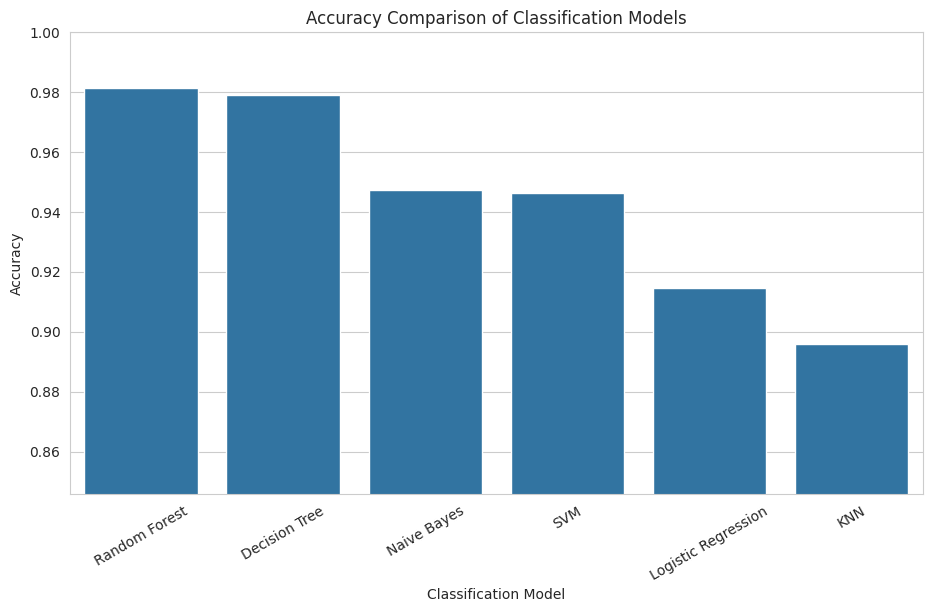

In [ ]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=30)

plt.ylim(
    max(0, results_df["Accuracy"].min() - 0.05),
    1
)

plt.show()

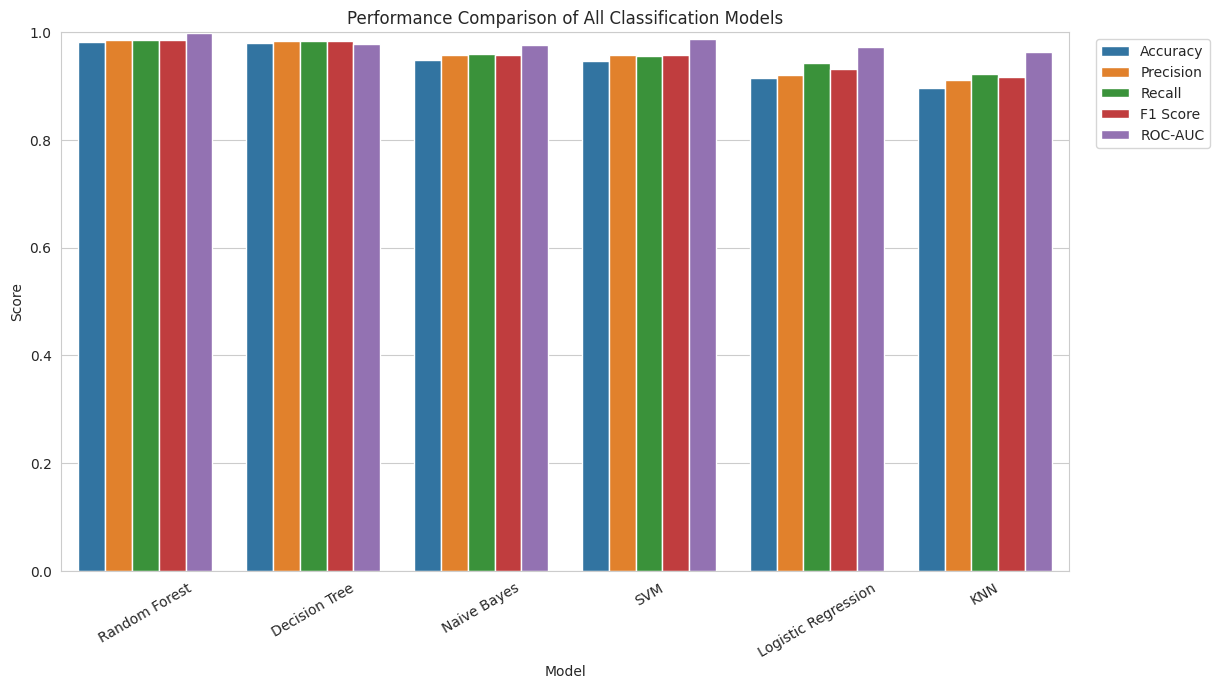

In [ ]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of All Classification Models")
plt.xlabel("Model")
plt.ylabel("Score")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.show()

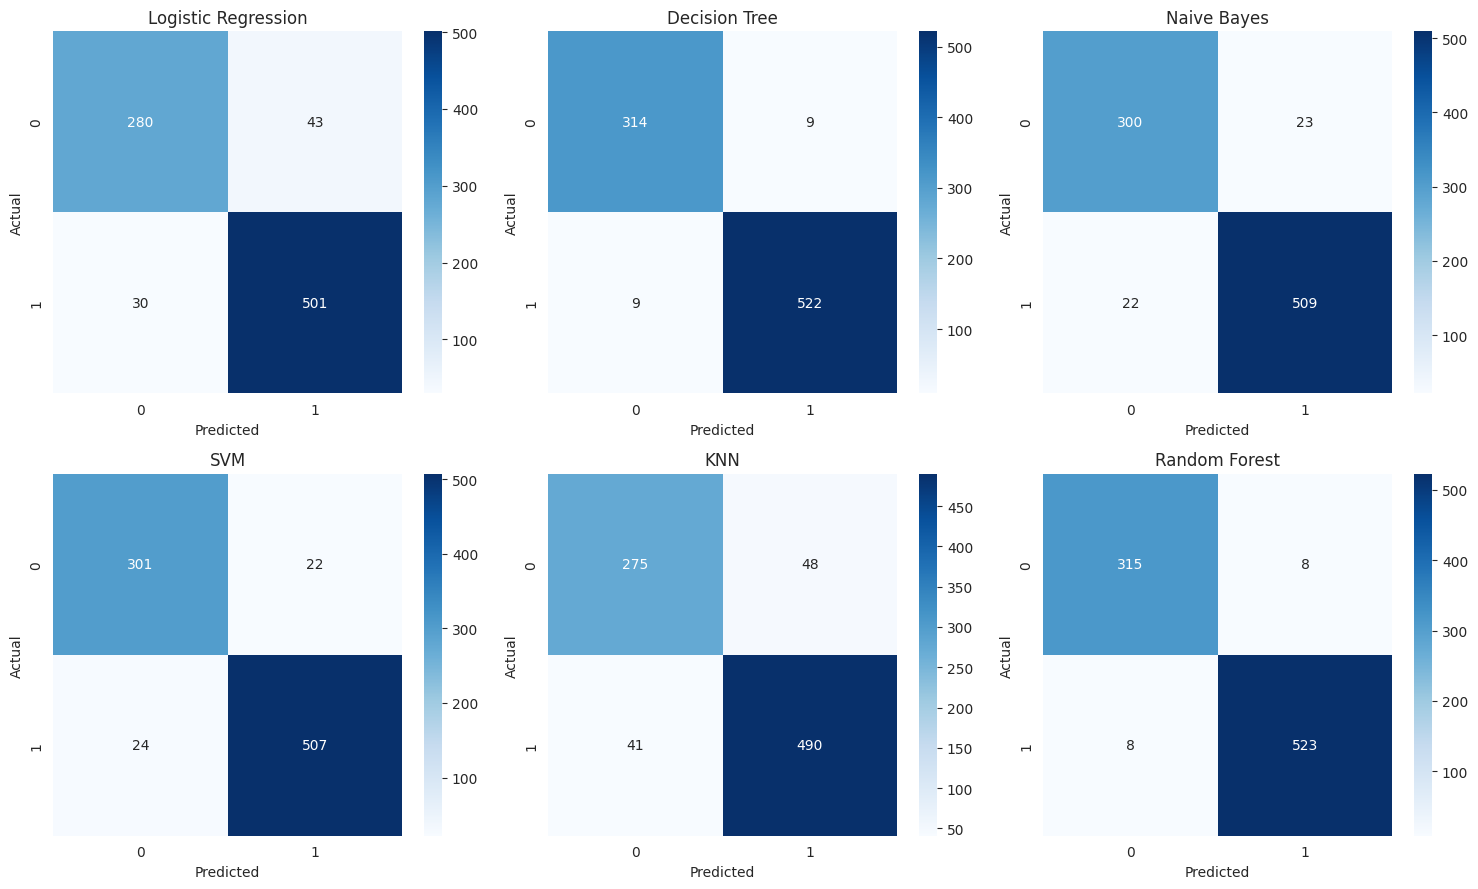

In [ ]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

axes = axes.ravel()

for i, (name, model) in enumerate(trained_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

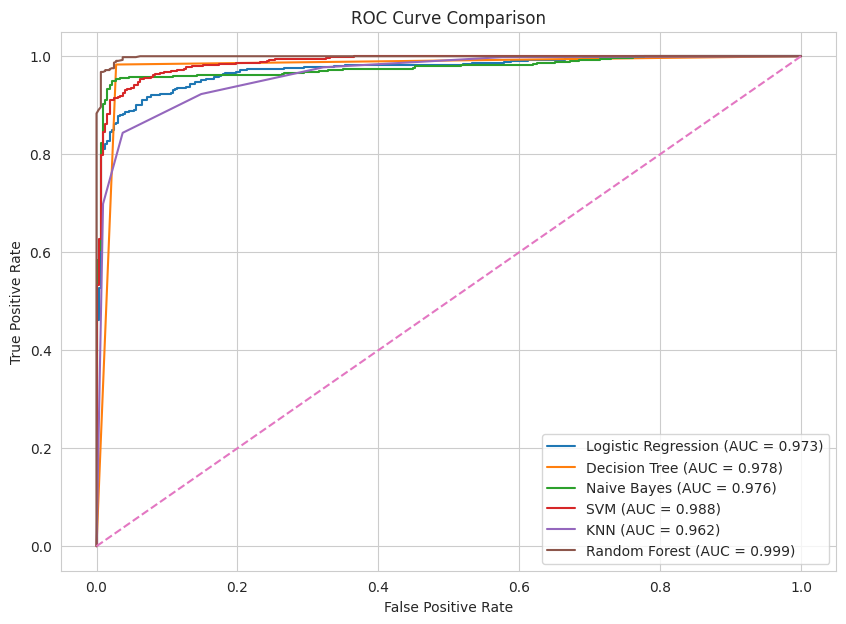

In [ ]:
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    y_probability = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_probability
    )

    auc_score = roc_auc_score(
        y_test,
        y_probability
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()

plt.show()

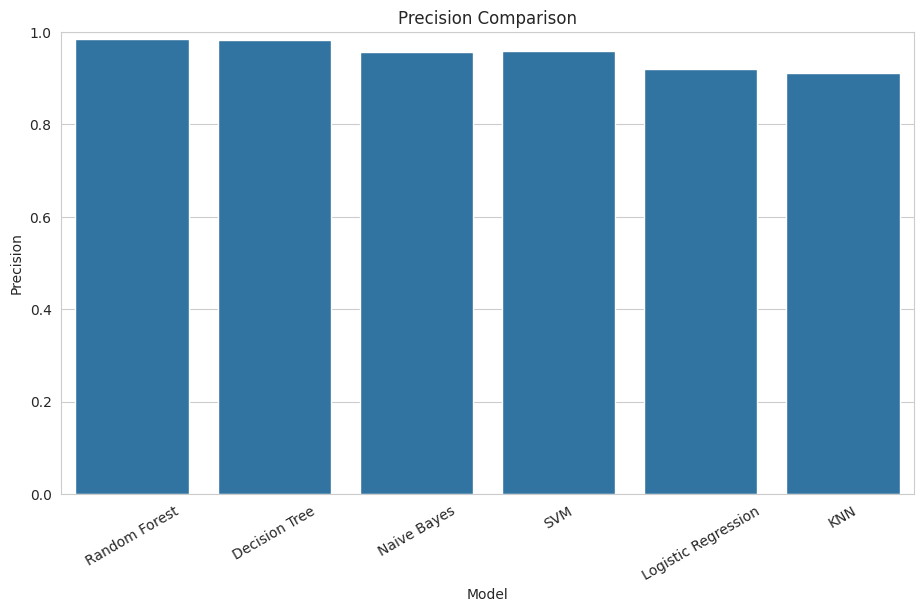

In [ ]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Precision"
)

plt.title("Precision Comparison")
plt.xlabel("Model")
plt.ylabel("Precision")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.show()

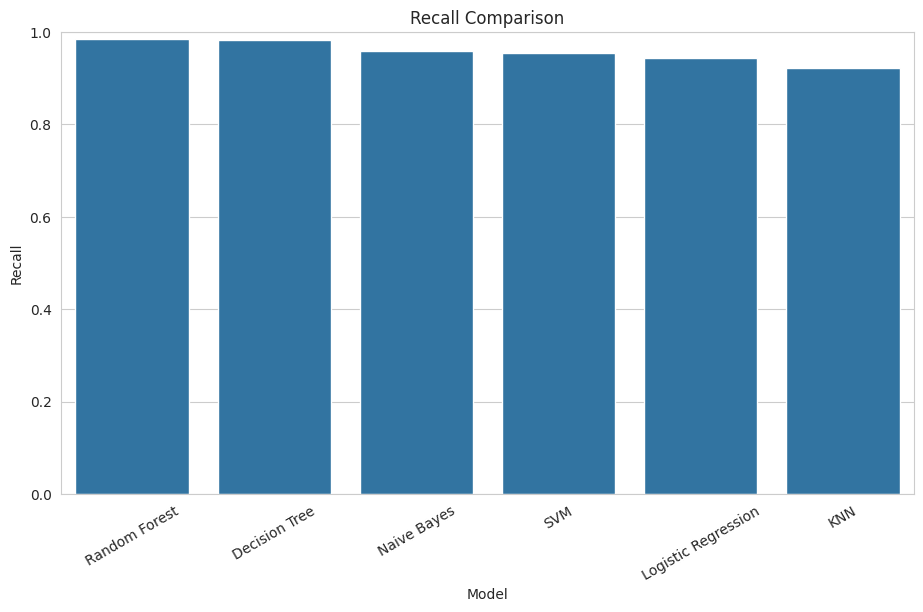

In [ ]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Recall"
)

plt.title("Recall Comparison")
plt.xlabel("Model")
plt.ylabel("Recall")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.show()

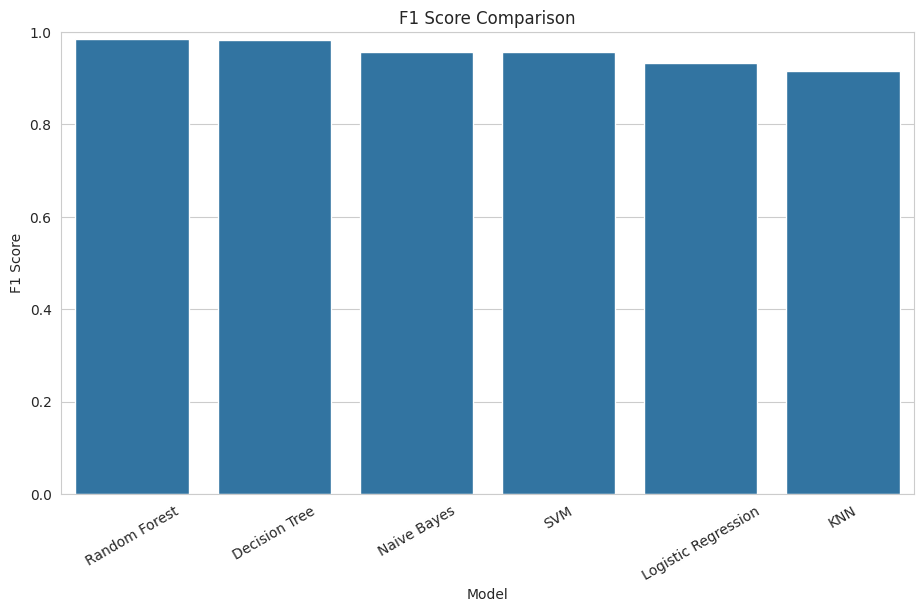

In [ ]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.title("F1 Score Comparison")
plt.xlabel("Model")
plt.ylabel("F1 Score")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.show()

In [ ]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Model with highest test accuracy:")
print(best_model_name)

print(
    "\nAccuracy:",
    round(
        results_df.iloc[0]["Accuracy"] * 100,
        2
    ),
    "%"
)

Model with highest test accuracy:
Random Forest

Accuracy: 98.13 %


In [ ]:
best_predictions = best_model.predict(X_test)

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=[
            "Rejected",
            "Approved"
        ]
    )
)

              precision    recall  f1-score   support

    Rejected       0.98      0.98      0.98       323
    Approved       0.98      0.98      0.98       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



In [ ]:
dt_model = trained_models["Decision Tree"]

feature_names = (
    dt_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = (
    dt_model
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df.head(15)

,Feature,Importance
4,num__cibil_score,0.813971
3,num__loan_term,0.085633
2,num__loan_amount,0.043170
1,num__income_annum,0.031135
7,num__luxury_assets_value,0.014384
5,num__residential_assets_value,0.004853
0,num__no_of_dependents,0.004005
6,num__commercial_assets_value,0.001395
12,cat__self_employed_ Yes,0.000831
9,cat__education_ Graduate,0.000623


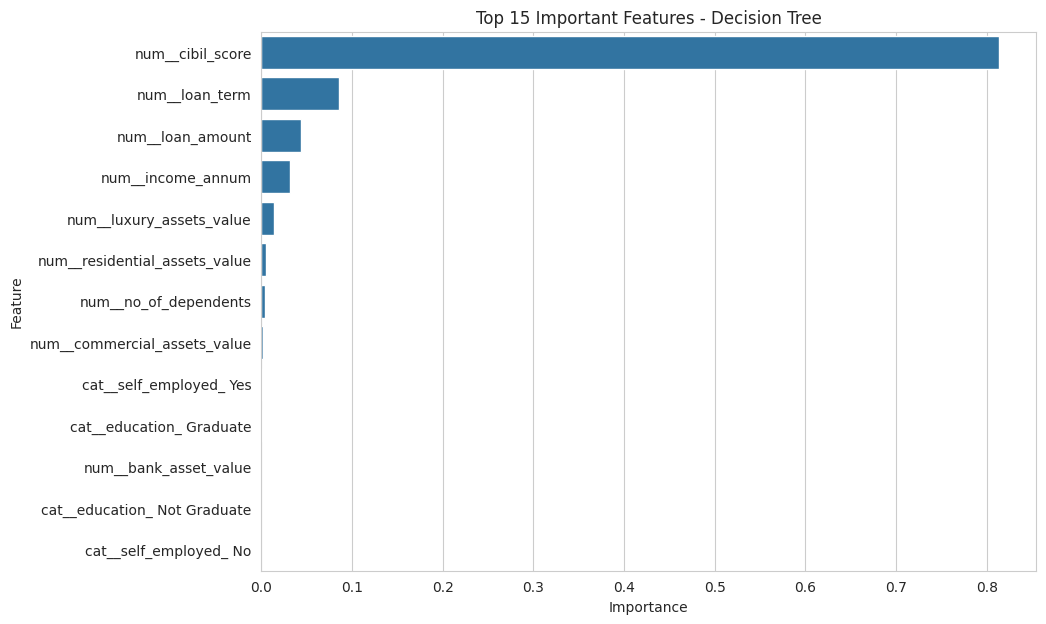

In [ ]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 15 Important Features - Decision Tree"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [ ]:
rf_model = trained_models["Random Forest"]

rf_feature_names = (
    rf_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

rf_importance = (
    rf_model
    .named_steps["classifier"]
    .feature_importances_
)

rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importance
})

rf_importance_df = rf_importance_df.sort_values(
    by="Importance",
    ascending=False
)

rf_importance_df.head(15)

,Feature,Importance
4,num__cibil_score,0.795536
3,num__loan_term,0.061487
2,num__loan_amount,0.030929
1,num__income_annum,0.019543
7,num__luxury_assets_value,0.019452
5,num__residential_assets_value,0.019255
6,num__commercial_assets_value,0.019108
8,num__bank_asset_value,0.016857
0,num__no_of_dependents,0.009182
11,cat__self_employed_ No,0.002280


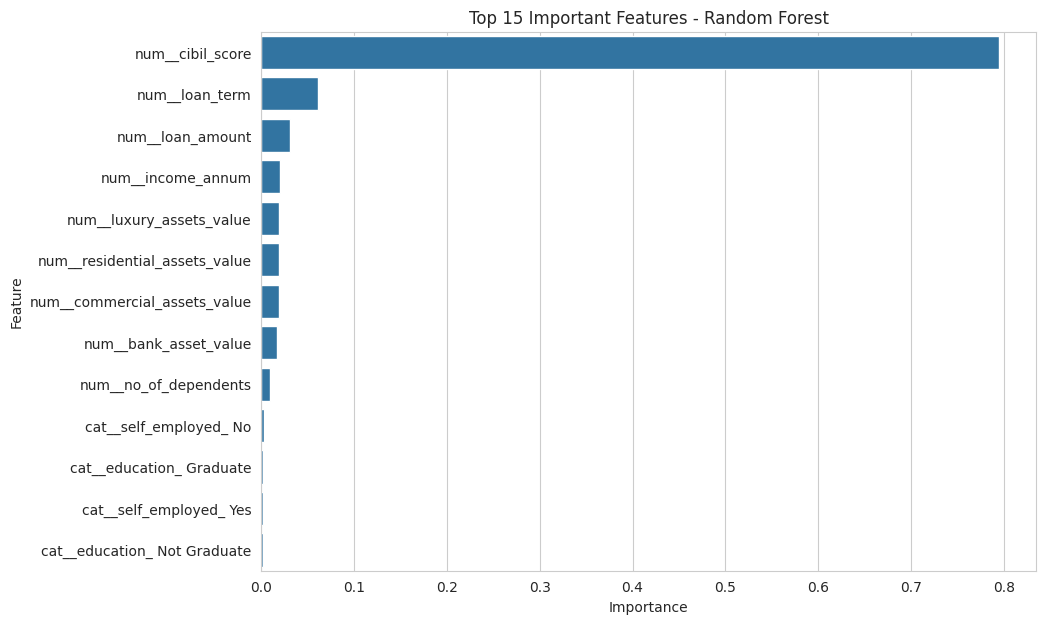

In [ ]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=rf_importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 15 Important Features - Random Forest"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

## Predicting with the Best Model

### Predict for a New Loan Applicant

In [ ]:
print("Enter details for a new loan applicant")
print("-" * 50)

no_of_dependents = int(
    input("Number of dependents: ")
)

education = input(
    "Education (Graduate/Not Graduate): "
).strip()

self_employed = input(
    "Self Employed (Yes/No): "
).strip()

income_annum = float(
    input("Annual income: ")
)

loan_amount = float(
    input("Loan amount: ")
)

loan_term = float(
    input("Loan term in years: ")
)

cibil_score = float(
    input("CIBIL score: ")
)

residential_assets_value = float(
    input("Residential assets value: ")
)

commercial_assets_value = float(
    input("Commercial assets value: ")
)

luxury_assets_value = float(
    input("Luxury assets value: ")
)

bank_asset_value = float(
    input("Bank asset value: ")
)

Enter details for a new loan applicant
--------------------------------------------------
Number of dependents: 12
Education (Graduate/Not Graduate): Graduate
Self Employed (Yes/No): Yes
Annual income: 1000000
Loan amount: 2000000
Loan term in years: 2
CIBIL score: 5
Residential assets value: 500000
Commercial assets value: 250000
Luxury assets value: 0
Bank asset value: 100000


In [ ]:
new_applicant = pd.DataFrame({
    "no_of_dependents": [no_of_dependents],
    "education": [education],
    "self_employed": [self_employed],
    "income_annum": [income_annum],
    "loan_amount": [loan_amount],
    "loan_term": [loan_term],
    "cibil_score": [cibil_score],
    "residential_assets_value": [
        residential_assets_value
    ],
    "commercial_assets_value": [
        commercial_assets_value
    ],
    "luxury_assets_value": [
        luxury_assets_value
    ],
    "bank_asset_value": [
        bank_asset_value
    ]
})

prediction = best_model.predict(
    new_applicant
)[0]

probability = best_model.predict_proba(
    new_applicant
)[0]

print("\n" + "=" * 50)

if prediction == 1:
    print("LOAN STATUS: APPROVED")
    print("Prediction: 1")
else:
    print("LOAN STATUS: REJECTED")
    print("Prediction: 0")

print(
    f"Probability of Rejection: {probability[0]*100:.2f}%"
)

print(
    f"Probability of Approval: {probability[1]*100:.2f}%"
)

print("=" * 50)


LOAN STATUS: REJECTED
Prediction: 0
Probability of Rejection: 59.50%
Probability of Approval: 40.50%


In [ ]:
final_comparison = results_df.copy()

final_comparison[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
]

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.981265,0.984934,0.984934,0.984934,0.998636
1,Decision Tree,0.978923,0.983051,0.983051,0.983051,0.977594
2,Naive Bayes,0.947307,0.956767,0.958569,0.957667,0.976497
3,SVM,0.946136,0.958412,0.954802,0.956604,0.987569
4,Logistic Regression,0.914520,0.920956,0.943503,0.932093,0.972550
5,KNN,0.895785,0.910781,0.922787,0.916745,0.962408


## Conclusion

In this project, machine learning classification algorithms were used to
predict whether a bank loan application would be approved or rejected.

The dataset contained applicant financial and credit-related information
such as annual income, loan amount, loan term, CIBIL score, employment
status, education and asset values.

The following classification algorithms were implemented:

1. Logistic Regression
2. Decision Tree
3. Naive Bayes
4. Support Vector Machine
5. K-Nearest Neighbors
6. Random Forest

The data was preprocessed by handling missing values, encoding categorical
variables and scaling numerical features where required.

Exploratory Data Analysis was performed using count plots, histograms,
boxplots, scatter plots, pair plots and a correlation heatmap.

The models were evaluated using:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- Confusion Matrix
- ROC Curve

The final model comparison table was used to determine which model achieved
the strongest test-set performance on the selected evaluation metrics.

The trained model can also be used to enter details of a new applicant and
predict whether the application is classified as Approved (1) or Rejected
(0).
